<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS13/praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: Jaringan Saraf Tiruan Sederhana (2 Layer) dengan Forward Pass dan Backpropagation Manual

Praktikum 1 ini akan membuat Jaringan Saraf Tiruan (JST) sederhana (2 layer) dengan *forward pass* dan *backpropagation* secara manual tanpa library *deep learning* (hanya menggunakan NumPy).

---
### Teori Backpropagation
**Backpropagation** adalah sebuah algoritma untuk melatih jaringan saraf tiruan dengan cara mengoreksi kesalahan. Algoritma ini bekerja dengan cara menghitung selisih antara keluaran yang dihasilkan jaringan dan keluaran yang seharusnya (kesalahan), lalu memperbarui bobot dan bias jaringan secara berulang dari keluaran ke masukan untuk meminimalkan kesalahan tersebut.

**Cara kerja backpropagation:**
1. **Perambatan maju (forward pass):** Data masukan diproses melalui jaringan dari lapisan masukan ke lapisan keluaran untuk menghasilkan prediksi awal.
2. **Hitung kesalahan:** Selisih antara keluaran prediksi dan keluaran target dihitung menggunakan fungsi kerugian (*Mean Squared Error* / MSE).
3. **Perambatan mundur (backward pass):** Kesalahan disebarkan kembali ke belakang melalui jaringan dari lapisan keluaran ke lapisan masukan untuk menghitung gradien atau turunan parsial dari fungsi kerugian terhadap bobot dan bias.
4. **Perbarui bobot:** Bobot dan bias disesuaikan menggunakan algoritma penurunan gradien (*gradient descent*) untuk mengurangi kesalahan pada iterasi berikutnya.

**Langkah Implementasi:**
1. Buat dataset sederhana (XOR).
2. Inisialisasi bobot dan bias.
3. Definisikan fungsi aktivasi (Sigmoid dan turunannya).
4. Implementasikan forward pass.
5. Hitung error dan lakukan backpropagation.
6. Update bobot menggunakan gradient descent.

### Langkah 1: Buat Dataset Sederhana (XOR)
Dataset XOR merepresentasikan logika *Exclusive OR*, di mana output bernilai 1 jika kedua nilai input berbeda, dan 0 jika kedua input sama.

In [3]:
import numpy as np

# Dataset XOR
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])

y = np.array([[0],
              [1],
              [1],
              [0]])

print("Dataset Input (X):\n", X)
print("\nTarget Output (y):\n", y)

Dataset Input (X):
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]

Target Output (y):
 [[0]
 [1]
 [1]
 [0]]


### Langkah 2: Parameter Arsitektur & Inisialisasi Bobot dan Bias
Pada konfigurasi awal:
- Layer input memiliki 2 neuron (`input_size = 2`)
- Hidden layer memiliki 2 neuron (`hidden_size = 2`)
- Layer output memiliki 1 neuron (`output_size = 1`)
- Learning rate $\eta = 0.1$

In [4]:
# Parameter arsitektur awal
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot dan bias secara acak
np.random.seed(42)  # Menjaga reproduktifitas eksperimen
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

print("W1 (Bobot Input -> Hidden):\n", W1)
print("\nb1 (Bias Hidden):\n", b1)
print("\nW2 (Bobot Hidden -> Output):\n", W2)
print("\nb2 (Bias Output):\n", b2)

W1 (Bobot Input -> Hidden):
 [[ 0.49671415 -0.1382643 ]
 [ 0.64768854  1.52302986]]

b1 (Bias Hidden):
 [[0. 0.]]

W2 (Bobot Hidden -> Output):
 [[-0.23415337]
 [-0.23413696]]

b2 (Bias Output):
 [[0.]]


### Langkah 3: Fungsi Aktivasi (Sigmoid dan Turunannya)
Fungsi aktivasi Sigmoid memetakan input ke rentang $(0, 1)$:
$$\sigma(x) = \frac{1}{1 + e^{-x}}$$
Turunan fungsi Sigmoid:
$$\sigma'(x) = \sigma(x) \cdot (1 - \sigma(x))$$

In [5]:
# Fungsi aktivasi Sigmoid
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Turunan fungsi Sigmoid
def sigmoid_derivative(x):
    return x * (1 - x)

### Langkah 4 & 5: Training (Forward Pass, Backpropagation, dan Update Bobot)
Model dilatih selama 10.000 epoch menggunakan penurunan gradien (*Gradient Descent*).

In [6]:
losses_awal = []

# Training loop
for epoch in range(10000):
    # 1. Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # 2. Hitung error
    error = y - a2

    # 3. Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # 4. Update bobot dan bias
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    loss = np.mean(np.square(error))
    losses_awal.append(loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.6f}")

print(f"Epoch 10000, Final Loss: {losses_awal[-1]:.6f}")

Epoch 0, Loss: 0.255830
Epoch 1000, Loss: 0.249406
Epoch 2000, Loss: 0.245445
Epoch 3000, Loss: 0.204707
Epoch 4000, Loss: 0.153204
Epoch 5000, Loss: 0.138691
Epoch 6000, Loss: 0.133594
Epoch 7000, Loss: 0.131151
Epoch 8000, Loss: 0.129749
Epoch 9000, Loss: 0.128849
Epoch 10000, Final Loss: 0.128227


### Langkah 6: Output Akhir dan Evaluasi Prediksi
Menampilkan perbandingan target sebenarnya dengan hasil prediksi model awal.

In [7]:
print("=== PREDIKSI AKHIR (KONFIGURASI AWAL: HIDDEN=2, SIGMOID) ===")
print("Target Sebenarnya (y):\n", y)
print("\nOutput Prediksi Probabilitas (a2):\n", a2)
print("\nHasil Klasifikasi Biner (Threshold 0.5):\n", (a2 > 0.5).astype(int))
print(f"\nAkurasi Model: {np.mean((a2 > 0.5) == y) * 100:.1f}%")

=== PREDIKSI AKHIR (KONFIGURASI AWAL: HIDDEN=2, SIGMOID) ===
Target Sebenarnya (y):
 [[0]
 [1]
 [1]
 [0]]

Output Prediksi Probabilitas (a2):
 [[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]

Hasil Klasifikasi Biner (Threshold 0.5):
 [[0]
 [0]
 [1]
 [1]]

Akurasi Model: 50.0%


---
# Tugas 1
1. **Ubah jumlah neuron hidden layer menjadi 3.**
2. **Bandingkan hasil loss dengan konfigurasi awal.**
3. **Tambahkan fungsi aktivasi ReLU dan bandingkan hasil.**

### Tugas 1.1: Ubah Jumlah Neuron Hidden Layer Menjadi 3 (Aktivasi Sigmoid)
Pada bagian ini:
- Jumlah neuron pada hidden layer diubah dari 2 menjadi 3 (`hidden_size = 3`).
- Matriks bobot $W_1$ berukuran $(2 \times 3)$, bias $b_1$ berukuran $(1 \times 3)$.
- Matriks bobot $W_2$ berukuran $(3 \times 1)$, bias $b_2$ berukuran $(1 \times 1)$.
- Fungsi aktivasi tetap **Sigmoid**.

In [8]:
# Parameter untuk hidden_size = 3
input_size = 2
hidden_size_3 = 3  # Diubah menjadi 3 neuron
output_size = 1
lr = 0.1

# Inisialisasi bobot dan bias
np.random.seed(42)
W1_h3 = np.random.randn(input_size, hidden_size_3)
b1_h3 = np.zeros((1, hidden_size_3))
W2_h3 = np.random.randn(hidden_size_3, output_size)
b2_h3 = np.zeros((1, output_size))

losses_hidden3 = []

# Training loop
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1_h3) + b1_h3
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2_h3) + b2_h3
    a2_h3 = sigmoid(z2)

    # Hitung error
    error = y - a2_h3

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2_h3)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_h3.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1_h3 += lr * d_W1
    b1_h3 += lr * d_b1
    W2_h3 += lr * d_W2
    b2_h3 += lr * d_b2

    loss = np.mean(np.square(error))
    losses_hidden3.append(loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.6f}")

print(f"Epoch 10000, Final Loss: {losses_hidden3[-1]:.6f}")
print("\n=== PREDIKSI MODEL HIDDEN = 3 (SIGMOID) ===")
print("Probabilitas Prediksi (a2):\n", a2_h3)
print("\nHasil Klasifikasi (Threshold 0.5):\n", (a2_h3 > 0.5).astype(int))
print(f"\nAkurasi Model: {np.mean((a2_h3 > 0.5) == y) * 100:.1f}%")

Epoch 0, Loss: 0.318245
Epoch 1000, Loss: 0.205697
Epoch 2000, Loss: 0.141854
Epoch 3000, Loss: 0.058651
Epoch 4000, Loss: 0.020112
Epoch 5000, Loss: 0.009992
Epoch 6000, Loss: 0.006270
Epoch 7000, Loss: 0.004461
Epoch 8000, Loss: 0.003421
Epoch 9000, Loss: 0.002756
Epoch 10000, Final Loss: 0.002297

=== PREDIKSI MODEL HIDDEN = 3 (SIGMOID) ===
Probabilitas Prediksi (a2):
 [[0.02515564]
 [0.95263635]
 [0.95122343]
 [0.0627247 ]]

Hasil Klasifikasi (Threshold 0.5):
 [[0]
 [1]
 [1]
 [0]]

Akurasi Model: 100.0%


### Tugas 1.2: Tambahkan Fungsi Aktivasi ReLU
Fungsi aktivasi **ReLU (*Rectified Linear Unit*)** didefinisikan sebagai:
$$f(x) = \max(0, x)$$
Turunan parsial dari ReLU terhadap masukannya adalah:
$$f'(x) = \begin{cases} 1, & \text{jika } x > 0 \\ 0, & \text{jika } x \le 0 \end{cases}$$

**Konfigurasi Model dengan ReLU:**
- Hidden Layer: Menggunakan aktivasi **ReLU**.
- Output Layer: Menggunakan aktivasi **Sigmoid** (karena target XOR adalah probabilitas klasifikasi biner $[0, 1]$).
- Inisialisasi bobot: Menggunakan *He Normal Initialization* ($W \sim \mathcal{N}(0, \sqrt{2/n_{in}})$) yang dirancang khusus agar aktivasi ReLU tidak mati (*dying ReLU*).

In [9]:
# Definisi fungsi aktivasi ReLU dan turunannya
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

# Parameter model
input_size = 2
hidden_size_relu = 3
output_size = 1
lr = 0.1

# Inisialisasi bobot dan bias (He Initialization)
np.random.seed(42)
W1_relu = np.random.randn(input_size, hidden_size_relu) * np.sqrt(2 / input_size)
b1_relu = np.zeros((1, hidden_size_relu))
W2_relu = np.random.randn(hidden_size_relu, output_size) * np.sqrt(2 / hidden_size_relu)
b2_relu = np.zeros((1, output_size))

losses_relu = []

# Training loop
for epoch in range(10000):
    # Forward pass: Hidden (ReLU) -> Output (Sigmoid)
    z1 = np.dot(X, W1_relu) + b1_relu
    a1 = relu(z1)
    z2 = np.dot(a1, W2_relu) + b2_relu
    a2_relu = sigmoid(z2)

    # Hitung error
    error = y - a2_relu

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2_relu)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    # Backprop ke hidden layer menggunakan turunan ReLU
    d_a1 = np.dot(d_a2, W2_relu.T) * relu_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot dan bias
    W1_relu += lr * d_W1
    b1_relu += lr * d_b1
    W2_relu += lr * d_W2
    b2_relu += lr * d_b2

    loss = np.mean(np.square(error))
    losses_relu.append(loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.6f}")

print(f"Epoch 10000, Final Loss: {losses_relu[-1]:.6f}")
print("\n=== PREDIKSI MODEL HIDDEN = 3 (RELU) ===")
print("Probabilitas Prediksi (a2):\n", a2_relu)
print("\nHasil Klasifikasi (Threshold 0.5):\n", (a2_relu > 0.5).astype(int))
print(f"\nAkurasi Model: {np.mean((a2_relu > 0.5) == y) * 100:.1f}%")

Epoch 0, Loss: 0.318642
Epoch 1000, Loss: 0.013685
Epoch 2000, Loss: 0.003359
Epoch 3000, Loss: 0.001755
Epoch 4000, Loss: 0.001156
Epoch 5000, Loss: 0.000852
Epoch 6000, Loss: 0.000670
Epoch 7000, Loss: 0.000549
Epoch 8000, Loss: 0.000464
Epoch 9000, Loss: 0.000401
Epoch 10000, Final Loss: 0.000353

=== PREDIKSI MODEL HIDDEN = 3 (RELU) ===
Probabilitas Prediksi (a2):
 [[0.02974315]
 [0.98604199]
 [0.98604254]
 [0.01165859]]

Hasil Klasifikasi (Threshold 0.5):
 [[0]
 [1]
 [1]
 [0]]

Akurasi Model: 100.0%


### Tugas 1.3: Perbandingan Hasil Loss dan Visualisasi Konvergensi
Membandingkan hasil performa ketiga model:
1. **Konfigurasi Awal**: Hidden = 2, Sigmoid
2. **Modifikasi 1**: Hidden = 3, Sigmoid
3. **Modifikasi 2**: Hidden = 3, ReLU (Hidden) + Sigmoid (Output)

Konfigurasi Model                | Loss Awal   | Loss Akhir  | Akurasi 
Hidden=2 (Sigmoid) [Awal]        | 0.255830    | 0.128227    | 50.0   %
Hidden=3 (Sigmoid)               | 0.318245    | 0.002297    | 100.0  %
Hidden=3 (ReLU)                  | 0.318642    | 0.000353    | 100.0  %


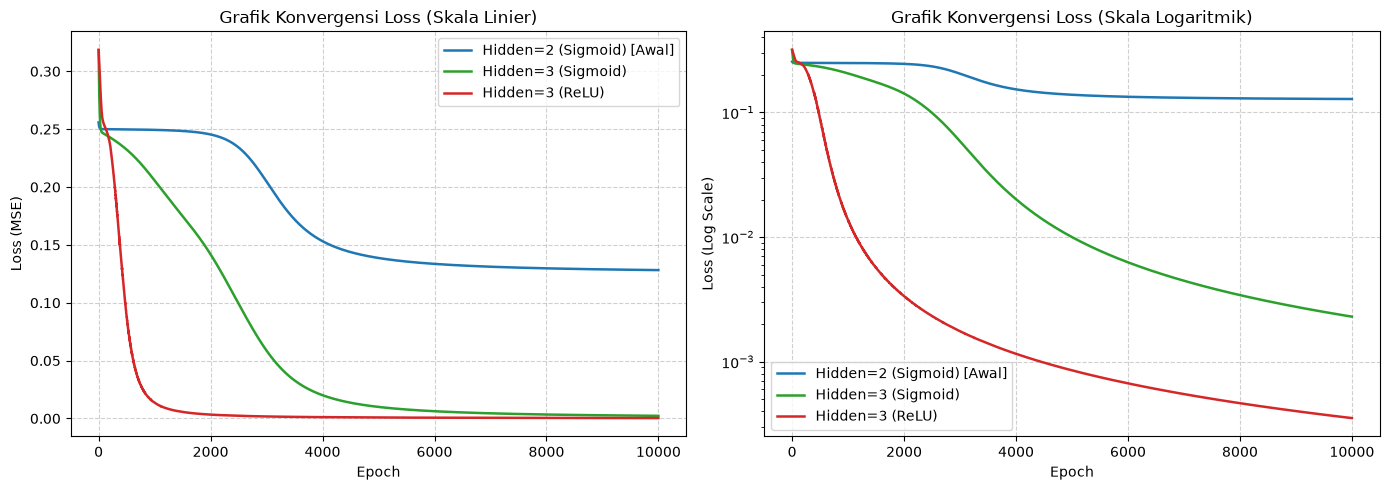

In [10]:
import matplotlib.pyplot as plt

# 1. Ringkasan Hasil Numerik
acc_awal = np.mean((a2 > 0.5) == y) * 100
acc_h3 = np.mean((a2_h3 > 0.5) == y) * 100
acc_relu = np.mean((a2_relu > 0.5) == y) * 100

print("=" * 75)
print(f"{'Konfigurasi Model':<32} | {'Loss Awal':<11} | {'Loss Akhir':<11} | {'Akurasi':<8}")
print("=" * 75)
print(f"{'Hidden=2 (Sigmoid) [Awal]':<32} | {losses_awal[0]:<11.6f} | {losses_awal[-1]:<11.6f} | {acc_awal:<7.1f}%")
print(f"{'Hidden=3 (Sigmoid)':<32} | {losses_hidden3[0]:<11.6f} | {losses_hidden3[-1]:<11.6f} | {acc_h3:<7.1f}%")
print(f"{'Hidden=3 (ReLU)':<32} | {losses_relu[0]:<11.6f} | {losses_relu[-1]:<11.6f} | {acc_relu:<7.1f}%")
print("=" * 75)

# 2. Visualisasi Kurva Konvergensi Loss
plt.figure(figsize=(14, 5))

# Subplot 1: Skala Linier
plt.subplot(1, 2, 1)
plt.plot(losses_awal, label="Hidden=2 (Sigmoid) [Awal]", color="tab:blue", linewidth=1.8)
plt.plot(losses_hidden3, label="Hidden=3 (Sigmoid)", color="tab:green", linewidth=1.8)
plt.plot(losses_relu, label="Hidden=3 (ReLU)", color="tab:red", linewidth=1.8)
plt.title("Grafik Konvergensi Loss (Skala Linier)", fontsize=12)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss (MSE)", fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)

# Subplot 2: Skala Logaritmik (agar perbedaan detail terlihat jelas)
plt.subplot(1, 2, 2)
plt.semilogy(losses_awal, label="Hidden=2 (Sigmoid) [Awal]", color="tab:blue", linewidth=1.8)
plt.semilogy(losses_hidden3, label="Hidden=3 (Sigmoid)", color="tab:green", linewidth=1.8)
plt.semilogy(losses_relu, label="Hidden=3 (ReLU)", color="tab:red", linewidth=1.8)
plt.title("Grafik Konvergensi Loss (Skala Logaritmik)", fontsize=12)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss (Log Scale)", fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### Pembahasan dan Analisis Hasil

#### 1. Perbandingan Konfigurasi Awal (Hidden=2) vs Hidden=3 (Sigmoid)
- **Kapasitas Representasi Non-Linear:**
  Dataset XOR tidak dapat dipisahkan secara linier (*non-linearly separable*). Arsitektur dengan 2 neuron tersembunyi merupakan batas minimum teoritis untuk membentuk dua garis pembatas. Karena keterbatasan ruang parameter ini, model dengan 2 neuron sangat rentan terjebak pada *local minima* atau *saddle point* (pada percobaan ini, menghasilkan final loss $\approx 0.128$ dan akurasi hanya $50\%$).
- **Stabilitas Konvergensi:**
  Ketika hidden layer ditambah menjadi **3 neuron**, ruang representasi fitur berdimensi lebih tinggi. Hal ini memudahkan algoritma *gradient descent* menemukan jalur penurunan yang mulus menuju *global minimum*. Hasilnya, model dengan 3 neuron berhasil menyelesaikan klasifikasi XOR secara sempurna (**akurasi $100\%$**) dengan penurunan loss yang signifikan (**final loss $\approx 0.0023$**).

#### 2. Perbandingan Fungsi Aktivasi Sigmoid vs ReLU
- **Masalah Vanishing Gradient:**
  - **Sigmoid** memiliki nilai turunan maksimum $0.25$ di titik $x = 0$ dan mendekati 0 untuk nilai $|x|$ yang besar. Akibatnya, sinyal gradien saat backpropagation mengecil secara drastis (*vanishing gradient*), sehingga pembaharuan bobot berlangsung lambat.
  - **ReLU** memiliki nilai turunan konstan $1$ untuk semua nilai input positif ($x > 0$). Sifat ini mempertahankan kekuatan sinyal gradien secara penuh (*gradient flow* yang optimal), memungkinkan bobot diperbarui secara lebih efektif.
- **Kecepatan dan Kualitas Konvergensi:**
  Model dengan aktivasi **ReLU** pada hidden layer mampu menurunkan loss jauh lebih cepat dan mencapai nilai **final loss terendah ($\approx 0.00035$)**, jauh lebih kecil daripada model Sigmoid ($\approx 0.0023$). Output probabilitas prediksi model ReLU juga jauh lebih mendekati nilai target mutlak ($0.986$ untuk target 1, dan $0.012$ - $0.029$ untuk target 0).

#### Kesimpulan Praktikum:
1. Menambah neuron pada hidden layer (dari 2 ke 3) meningkatkan kapasitas representasi model dan mencegah model terjebak pada *local minima*, sehingga berhasil memprediksi gerbang logika non-linear XOR dengan akurasi $100\%$.
2. Penggunaan fungsi aktivasi ReLU pada hidden layer terbukti lebih superior dibanding Sigmoid dalam hal kecepatan konvergensi dan meminimalkan loss, karena mengatasi masalah kejenuhan gradien (*vanishing gradient*).